In [ ]:
!pip install gdown
import gdown
import pandas as pd
# @title
P1_PATH = gdown.download("https://drive.google.com/uc?id=1J97S0GDy9bJVGO6Hi0c31q-BmpCGEn83", "Phase_1.xlsx", quiet=False)
P2_PATH = gdown.download("https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds", "Phase_2.xlsx", quiet=False)
P3_PATH = gdown.download("https://drive.google.com/uc?id=1pWZIKiGTNkph8zWW35gX-EqzKFy5eSWy", "Phase_3.xlsx", quiet=False)
df1 = pd.read_excel(P1_PATH)
df2 = pd.read_excel(P2_PATH)
df3 = pd.read_excel(P3_PATH)

Downloading...
From: https://drive.google.com/uc?id=1J97S0GDy9bJVGO6Hi0c31q-BmpCGEn83
To: /content/Phase_1.xlsx
100%|██████████| 115k/115k [00:00<00:00, 5.32MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds
From (redirected): https://docs.google.com/spreadsheets/d/1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds/export?format=xlsx
To: /content/Phase_2.xlsx
212kB [00:00, 29.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1pWZIKiGTNkph8zWW35gX-EqzKFy5eSWy
To: /content/Phase_3.xlsx
100%|██████████| 367k/367k [00:00<00:00, 7.07MB/s]


Downloading...
From: https://drive.google.com/uc?id=1J97S0GDy9bJVGO6Hi0c31q-BmpCGEn83
To: /content/Phase_1.xlsx
100%|██████████| 115k/115k [00:00<00:00, 7.27MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds
From (redirected): https://docs.google.com/spreadsheets/d/1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds/export?format=xlsx
To: /content/Phase_2.xlsx
212kB [00:00, 26.2MB/s]


Study 1 N = 600
Study 2 N = 603

RESULTS
  study  group_no                             condition  correct_n   n   percent    ci_low   ci_high
Study 1         1  Authentic audio\n+ authentic content        157 200 78.500000 72.297693 83.628124
Study 2         1  Authentic audio\n+ authentic content        157 200 78.500000 72.297693 83.628124
Study 1         2  Synthetic audio\n+ authentic content         71 200 35.500000 29.198628 42.347887
Study 2         2  Synthetic audio\n+ authentic content         84 201 41.791045 35.189008 48.700972
Study 1         3 Synthetic audio\n+ fabricated content         88 200 44.000000 37.297819 50.928325
Study 2         3 Synthetic audio\n+ fabricated content        124 202 61.386139 54.519232 67.828064

CHECK AGAINST EXPECTED VALUES
('Study 1', 1): calculated 78.5% | expected 78.5% | OK
('Study 2', 1): calculated 78.5% | expected 78.5% | OK
('Study 1', 2): calculated 35.5% | expected 35.5% | OK
('Study 2', 2): calculated 41.8% | expected 41.8% | OK
(

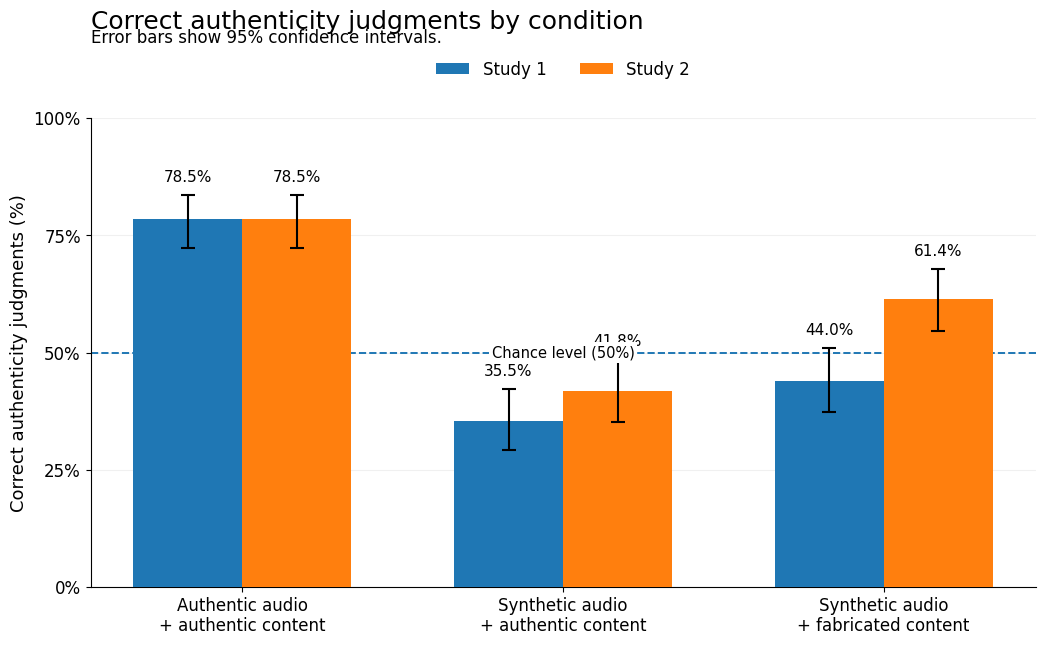

In [ ]:
# @title
# ============================================================
# FIGURE 1A — Correct authenticity judgments by condition
# Studies 1 and 2
# ONE CELL
# ============================================================

!pip -q install gdown openpyxl statsmodels

import gdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint


# ------------------------------------------------------------
# 1. DOWNLOAD STUDIES 1 AND 2
# ------------------------------------------------------------

P1_PATH = gdown.download(
    "https://drive.google.com/uc?id=1J97S0GDy9bJVGO6Hi0c31q-BmpCGEn83",
    "Phase_1.xlsx",
    quiet=False
)

P2_PATH = gdown.download(
    "https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds",
    "Phase_2.xlsx",
    quiet=False
)


# ------------------------------------------------------------
# 2. READ DATA
# ------------------------------------------------------------

p1 = pd.read_excel(P1_PATH)
p2 = pd.read_excel(P2_PATH)

print("Study 1 N =", len(p1))
print("Study 2 N =", len(p2))


# ------------------------------------------------------------
# 3. DEFINE CONDITIONS AND CORRECTNESS
#
# group_no:
# 1 = Authentic audio + authentic content
# 2 = Synthetic audio + authentic content
# 3 = Synthetic audio + fabricated content
#
# realness_perception:
# 1 = participant judged clip REAL
# 0 = participant judged clip FAKE
# ------------------------------------------------------------

condition_labels = {
    1: "Authentic audio\n+ authentic content",
    2: "Synthetic audio\n+ authentic content",
    3: "Synthetic audio\n+ fabricated content"
}


def prepare_study(df, study_name):

    d = df.copy()

    d = d[
        d["group_no"].isin([1, 2, 3]) &
        d["realness_perception"].isin([0, 1])
    ].copy()

    d["condition"] = d["group_no"].map(condition_labels)

    # Correct judgment:
    # authentic clip -> participant should say REAL
    # synthetic clip -> participant should say FAKE
    d["correct"] = np.where(
        d["group_no"] == 1,
        d["realness_perception"] == 1,
        d["realness_perception"] == 0
    ).astype(int)

    d["study"] = study_name

    return d


d1 = prepare_study(p1, "Study 1")
d2 = prepare_study(p2, "Study 2")

data = pd.concat([d1, d2], ignore_index=True)


# ------------------------------------------------------------
# 4. CALCULATE % CORRECT AND WILSON 95% CI
# ------------------------------------------------------------

summary = (
    data
    .groupby(
        ["study", "group_no", "condition"],
        observed=True
    )["correct"]
    .agg(
        correct_n="sum",
        n="count"
    )
    .reset_index()
)

summary["percent"] = (
    100 * summary["correct_n"] / summary["n"]
)


# Wilson 95% confidence intervals
ci = summary.apply(
    lambda r: proportion_confint(
        count=int(r["correct_n"]),
        nobs=int(r["n"]),
        alpha=0.05,
        method="wilson"
    ),
    axis=1
)

summary["ci_low"] = [100 * x[0] for x in ci]
summary["ci_high"] = [100 * x[1] for x in ci]

summary = (
    summary
    .sort_values(["group_no", "study"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. PRINT RESULTS
# ------------------------------------------------------------

print("\nRESULTS")

print(
    summary[
        [
            "study",
            "group_no",
            "condition",
            "correct_n",
            "n",
            "percent",
            "ci_low",
            "ci_high"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 6. CHECK EXPECTED VALUES
# ------------------------------------------------------------

expected = {
    ("Study 1", 1): 78.5,
    ("Study 1", 2): 35.5,
    ("Study 1", 3): 44.0,

    ("Study 2", 1): 78.5,
    ("Study 2", 2): 41.8,
    ("Study 2", 3): 61.4
}

print("\nCHECK AGAINST EXPECTED VALUES")

all_match = True

for _, r in summary.iterrows():

    key = (
        r["study"],
        int(r["group_no"])
    )

    actual = round(r["percent"], 1)
    expected_value = expected[key]

    match = np.isclose(
        actual,
        expected_value,
        atol=0.1
    )

    if not match:
        all_match = False

    print(
        f"{key}: "
        f"calculated {actual:.1f}% | "
        f"expected {expected_value:.1f}% | "
        f"{'OK' if match else 'CHECK'}"
    )

if all_match:
    print("\n✓ All percentages match the previous analysis.")
else:
    print("\n⚠ Check values before using the figure.")


# ============================================================
# 7. DRAW FIGURE
# ============================================================

conditions = [
    "Authentic audio\n+ authentic content",
    "Synthetic audio\n+ authentic content",
    "Synthetic audio\n+ fabricated content"
]

studies = [
    "Study 1",
    "Study 2"
]

x = np.arange(len(conditions))

width = 0.34


# Larger top margin for clean title/legend spacing
fig, ax = plt.subplots(
    figsize=(10.8, 7.0)
)


# ------------------------------------------------------------
# 8. BARS + ERROR BARS
# ------------------------------------------------------------

for i, study in enumerate(studies):

    temp = (
        summary[
            summary["study"] == study
        ]
        .set_index("condition")
        .reindex(conditions)
    )

    y = temp["percent"].to_numpy()

    ci_low = temp["ci_low"].to_numpy()
    ci_high = temp["ci_high"].to_numpy()

    yerr = np.vstack([
        y - ci_low,
        ci_high - y
    ])

    offset = (i - 0.5) * width

    bars = ax.bar(
        x + offset,
        y,
        width=width,

        yerr=yerr,

        capsize=5,

        error_kw={
            "elinewidth": 1.5,
            "capthick": 1.5
        },

        label=study,

        zorder=3
    )


    # --------------------------------------------------------
    # PERCENTAGE LABELS
    #
    # Put labels ABOVE the upper CI,
    # NOT directly above the bar.
    # --------------------------------------------------------

    for bar, value, upper_ci in zip(
        bars,
        y,
        ci_high
    ):

        ax.text(
            bar.get_x() + bar.get_width()/2,

            upper_ci + 2.2,

            f"{value:.1f}%",

            ha="center",
            va="bottom",

            fontsize=11,

            zorder=5
        )


# ============================================================
# 9. CHANCE LEVEL
# ============================================================

# Draw line behind bars/text
ax.axhline(
    y=50,

    linestyle="--",

    linewidth=1.4,

    zorder=1
)


# Put label in the CENTRE of the figure.
# White background breaks the dashed line around the text.
ax.text(
    x=1.0,
    y=50,

    s="Chance level (50%)",

    ha="center",
    va="center",

    fontsize=10.5,

    bbox=dict(
        facecolor="white",
        edgecolor="none",
        pad=2.0
    ),

    zorder=6
)


# ============================================================
# 10. AXES
# ============================================================

ax.set_ylim(
    0,
    100
)

ax.set_ylabel(
    "Correct authenticity judgments (%)",
    fontsize=13
)


ax.set_xticks(x)

ax.set_xticklabels(
    conditions,
    fontsize=12,
    linespacing=1.15
)


ax.set_yticks(
    [0, 25, 50, 75, 100]
)

ax.set_yticklabels(
    ["0%", "25%", "50%", "75%", "100%"],
    fontsize=12
)


# ============================================================
# 11. TITLE AND SUBTITLE
# ============================================================

fig.suptitle(
    "Correct authenticity judgments by condition",

    x=0.105,
    y=0.975,

    ha="left",

    fontsize=18
)


fig.text(
    0.105,
    0.928,

    "Error bars show 95% confidence intervals.",

    ha="left",

    fontsize=12
)


# ============================================================
# 12. LEGEND
# ============================================================

ax.legend(
    frameon=False,

    ncol=2,

    loc="upper center",

    bbox_to_anchor=(0.5, 1.155),

    fontsize=12,

    columnspacing=2
)


# ============================================================
# 13. CLEAN PNAS-STYLE FORMATTING
# ============================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


ax.grid(
    axis="y",
    linewidth=0.8,
    alpha=0.18,

    zorder=0
)

ax.set_axisbelow(True)


# More whitespace at top and bottom
plt.subplots_adjust(
    top=0.82,
    left=0.105,
    right=0.98,
    bottom=0.15
)


# ============================================================
# 14. SAVE
# ============================================================

plt.savefig(
    "Figure_1A_authenticity_discernment.png",

    dpi=600,

    bbox_inches="tight"
)


plt.savefig(
    "Figure_1A_authenticity_discernment.pdf",

    bbox_inches="tight"
)


plt.show()